In [34]:
import cv2 
import tensorflow as tf
import os
import numpy as np 


data_dir = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset'
    
valid_extensions = ['.jpeg', '.jpg', '.png' ,'bmp']

#test function
def is_valid_image(file_path):
    # 1. Check if the file extension is correct
    ext = os.path.splitext(file_path)[1].lower()
    if ext not in valid_extensions:
        return False
        
    # try opening the image with OpenCV
    img = cv2.imread(file_path)
    if img is None:
        return False
        
    return True

In [35]:
os.listdir(data_dir)

['Local', 'Export', 'Rotten']

In [3]:
#remove the bad images
for dir1 in os.listdir(data_dir):
    # print(dir1)
    for img in os.listdir(os.path.join(data_dir,dir1 )):
        full_img_path = os.path.join(data_dir, dir1,  img)
        if not is_valid_image(full_img_path):
            os.remove(full_img_path)

KeyboardInterrupt: 

In [7]:
!pip install split-folders

In [8]:
import splitfolders
from matplotlib import pyplot as plt

In [36]:
input_folder = '/kaggle/input/datasets/mohamedafkir90/tomato-quality-classification/Clean_tomato_dataset'
output_folder = '/kaggle/working/tomato_split' # Save to the writable directory

splitfolders.ratio(input_folder, 
                   output=output_folder, 
                   seed=42, 
                   ratio=(.8, .1, .1), # (train, val, test)
                   group_prefix=None, 
                   move=False) # Use False to copy files

Copying files: 15408 files [00:32, 468.03 files/s] 


In [37]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224) 

train_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/working/tomato_split/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_ds.class_names
print("\n classes are:", class_names)

Found 12324 files belonging to 3 classes.
Found 1539 files belonging to 3 classes.
Found 1545 files belonging to 3 classes.

 classes are: ['Export', 'Local', 'Rotten']


In [38]:
data_iterator = train_ds.as_numpy_iterator()

In [39]:
data_iterator

NumpyIterator(iterator=<tensorflow.python.data.ops.iterator_ops.OwnedIterator object at 0x78fbbfba8590>)

In [40]:
batch = data_iterator.next()

In [41]:
batch[1]

array([0, 0, 0, 1, 1, 1, 1, 2, 0, 0, 1, 1, 2, 1, 0, 2, 1, 0, 1, 2, 1, 0,
       0, 1, 2, 0, 2, 2, 2, 0, 1, 0], dtype=int32)

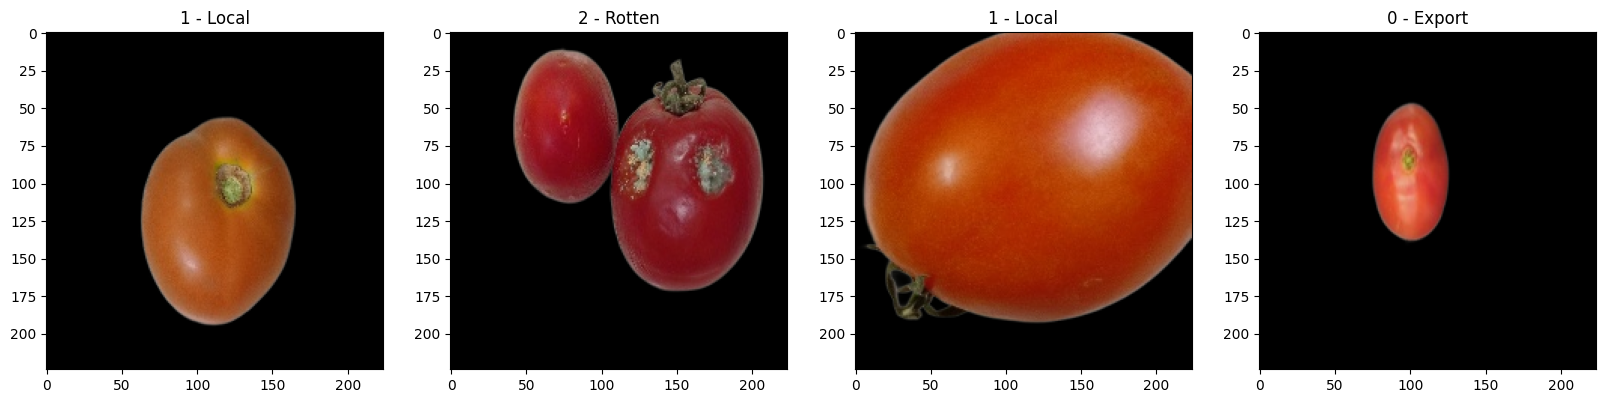

In [42]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))

start_idx = 11

for i in range(4):
    true_idx = start_idx + i 
    
    img = batch[0][true_idx]
    label_id = batch[1][true_idx]
    
    ax[i].imshow(img.astype(int))
    ax[i].title.set_text(f"{label_id} - {class_names[label_id]}")

#### Class 0: Export
#### Class 1: Local
#### Class 2: Rotten

In [43]:
Train_data = train_ds.map(lambda x,y: (x/255,y))

Val_data = val_ds.map(lambda x,y: (x/255,y))

Test_data = test_ds.map(lambda x,y: (x/255,y))

In [44]:
batch[0].max()

np.float32(255.0)

In [45]:
#scaled data min=0 and max = 1
scaled_batch = Train_data.as_numpy_iterator().next()
scaled_batch[0].max()

np.float32(1.0)

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense,GlobalAveragePooling2D, Flatten, Dropout

In [71]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

models_dir = "/kaggle/working/models"
os.makedirs(models_dir, exist_ok=True)
# Nettoyer la session
tf.keras.backend.clear_session() 

model = Sequential([
    Input(shape=(224, 224, 3)),
    
    # Block 1: Basic features
    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.2),  
    
    # Block 2: Intermediate features
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.3),  
    
    # Block 3: Complex features
    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.4), 
    
    Flatten(),
    
    # The "Brain" of the network
    Dense(256, activation='relu'),
    Dropout(0.5), 
    
    # Output: 3 Classes
    Dense(3, activation='softmax')
])

custom_optimizer = Adam(learning_rate=0.0001)

model.compile(optimizer=custom_optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

best_model= "/kaggle/working/models/Tomato_grading_BEST.keras"
callbacks = [
   
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    
   
    ModelCheckpoint(best_model, monitor='val_loss', save_best_only=True)
]

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,784,387 (98.36 MB)

 Trainable params: 25,784,387 (98.36 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
history = model.fit(
    Train_data, 
    validation_data=Val_data, 
    epochs=20, 
    callbacks=callbacks 
)

Epoch 1/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.5865 - loss: 0.8384 - val_accuracy: 0.8324 - val_loss: 0.4989
Epoch 2/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8548 - loss: 0.3761 - val_accuracy: 0.7973 - val_loss: 0.4107
Epoch 3/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8821 - loss: 0.3006 - val_accuracy: 0.8265 - val_loss: 0.3747
Epoch 4/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9028 - loss: 0.2544 - val_accuracy: 0.8629 - val_loss: 0.3219
Epoch 5/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9152 - loss: 0.2248 - val_accuracy: 0.7953 - val_loss: 0.4464
Epoch 6/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9206 - loss: 0.2036 - val_accuracy: 0.8863 - val_loss: 0.2820
Epoch 7/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9315 - loss: 0.1826 - val_accuracy: 0.9058 - val_loss: 0.2483
Epoch 8/20
386/386 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9322 - loss: 0.1732 - 

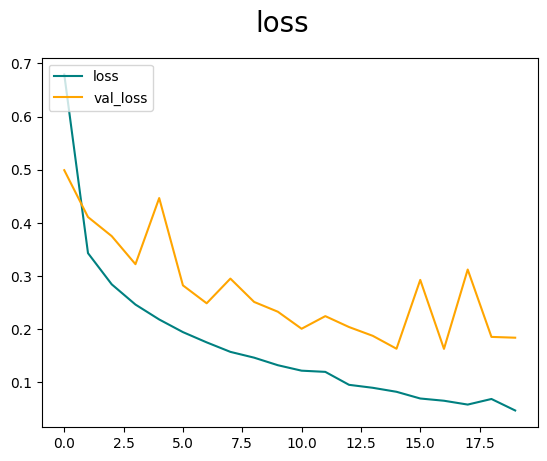

In [73]:
fig = plt.figure
plt.plot(history.history['loss'],color='teal', label='loss')
plt.plot(history.history['val_loss'],color='orange', label='val_loss')
plt.suptitle('loss',fontsize=20)
plt.legend(loc='upper left')
plt.show()

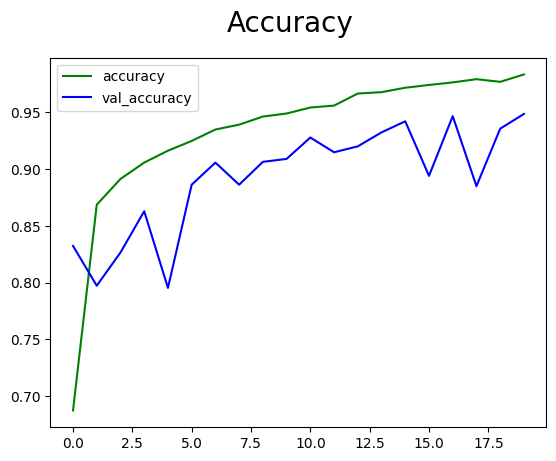

In [74]:
fig = plt.figure
plt.plot(history.history['accuracy'],color='green', label='accuracy')
plt.plot(history.history['val_accuracy'],color='blue', label='val_accuracy')
plt.suptitle('Accuracy',fontsize=20)
plt.legend(loc='upper left')
plt.show()

In [75]:
from sklearn.metrics import classification_report, confusion_matrix

y_true_all = []
y_pred_all = []


for batch in Test_data.as_numpy_iterator():
    X, y = batch
    
    
    y_predict_probs = model.predict(X, verbose=0)
    
    
    y_predict_classes = np.argmax(y_predict_probs, axis=1)
    
    
    y_true_all.extend(y)
    y_pred_all.extend(y_predict_classes)


print("Classification Report:")
print(classification_report(y_true_all, y_pred_all, target_names=['Local', 'Export', 'Rotten']))

Classification Report:
              precision    recall  f1-score   support

       Local       0.97      0.98      0.98       515
      Export       0.93      0.93      0.93       515
      Rotten       0.95      0.95      0.95       515

    accuracy                           0.95      1545
   macro avg       0.95      0.95      0.95      1545
weighted avg       0.95      0.95      0.95      1545



In [79]:
from tensorflow.keras.models import load_model
# save the model 
model.save(os.path.join(models_dir,'Tomato_grading_05.keras'))

In [80]:
model_path = '/kaggle/working/models/Tomato_grading_05.keras'

size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Model size: {size_mb:.2f} MB")

Model size: 295.13 MB
